# Data Analysis Project: Indonesian Humanities Exam Scores and University Selection
### Ported and Enhanced by: Siti Nurmila


In this section, we import the necessary scientific computing and visualization libraries (, , , and ). We also load the raw Humanities exam score dataset containing 61,202 rows of student choices.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Load the dataset
df_scores = pd.read_csv('score_humanities.csv')

print("--- DATASET DIMENSIONS ---")
print(df_scores.shape)
print("\n--- FIRST 5 RECORDS ---")
print(df_scores.head())


--- DATASET DIMENSIONS ---
(61202, 15)

--- FIRST 5 RECORDS ---
   Unnamed: 0  id_first_jurusan  id_first_university  id_second_jurusan  \
0           0           3322014                  332            3532154   
1           1           3212057                  321            3322022   
2           2           3722057                  372            1912042   
3           3           3212081                  321            3212301   
4           4           3812106                  381            3852034   

   id_second_university  id_user  score_eko  score_geo  score_kmb  score_kpu  \
0                   353       26        778        486        679        594   
1                   332       35        579        631        710        700   
2                   191       44        600        481        314        432   
3                   321       55        559        563        646        638   
4                   385      171        838        734        654        613   

   s

To analyze student preferences, we map the specific university IDs to their respected names (such as ITB, UI, Universitas Brawijaya, Universitas Airlangga, and Universitas Negeri Padang) and calculate the distribution of major selection

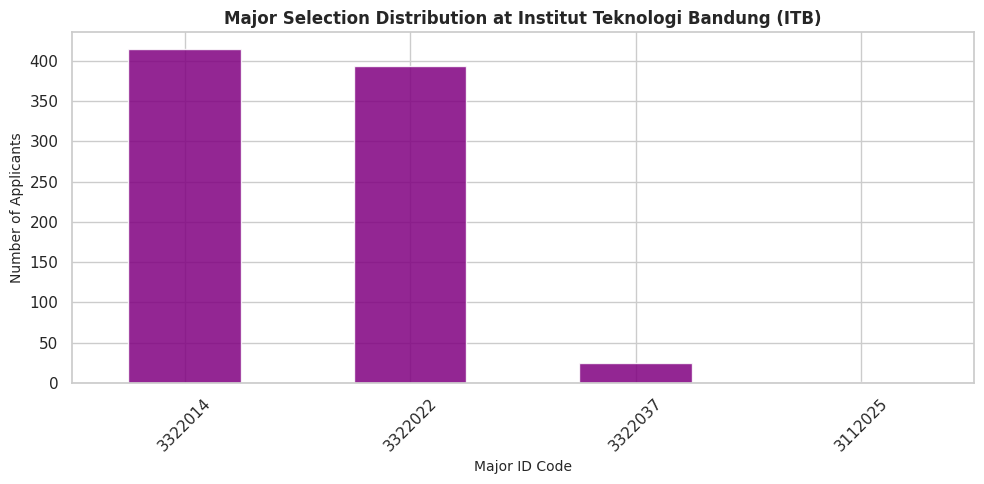

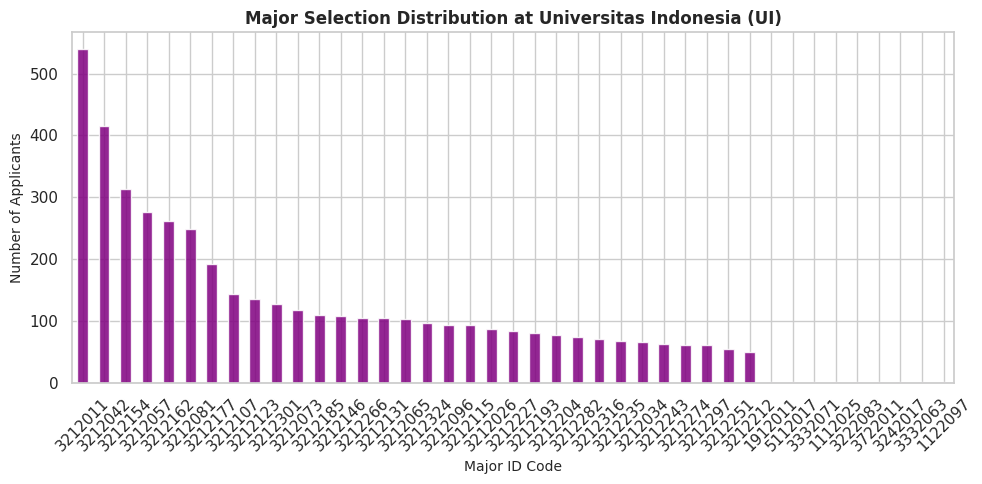

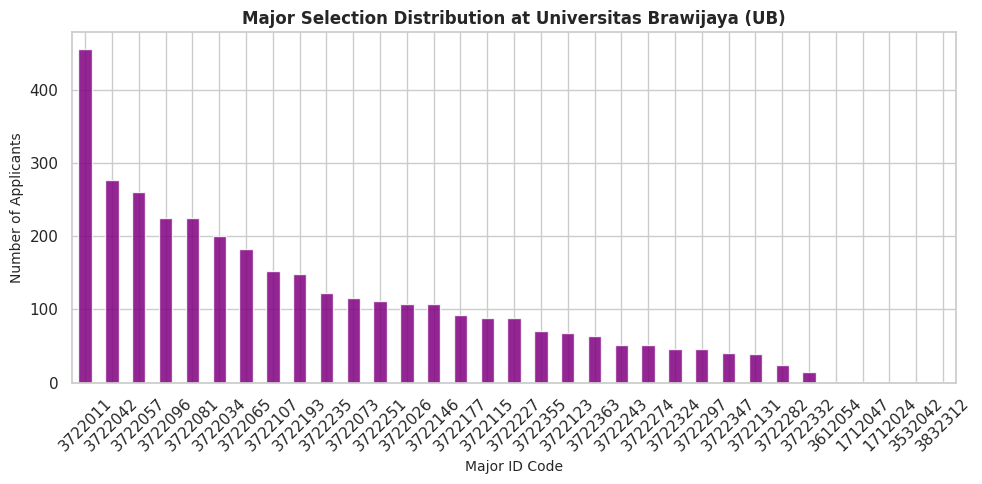

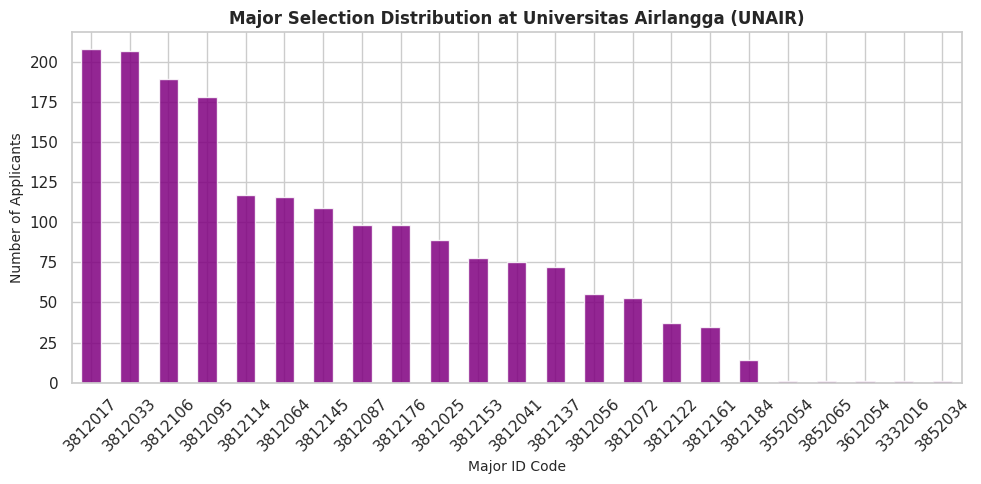

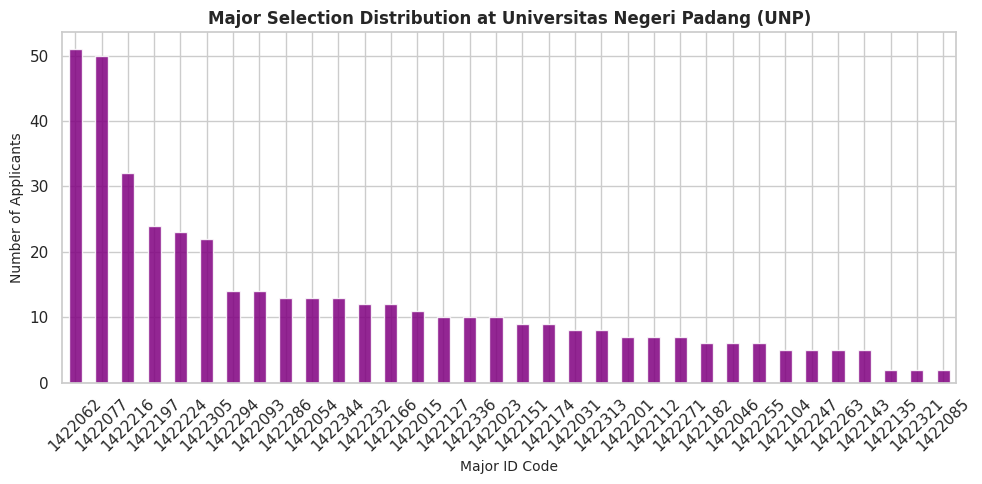

In [3]:
# Create a mapping dictionary for universities to make the code highly readable
uni_mapping = {
    332: "Institut Teknologi Bandung (ITB)",
    321: "Universitas Indonesia (UI)",
    372: "Universitas Brawijaya (UB)",
    381: "Universitas Airlangga (UNAIR)",
    142: "Universitas Negeri Padang (UNP)"
}

# Function to filter data and plot major choices automatically
def plot_major_distribution(uni_id, uni_name):
    # Filter dataset for first university choice
    df_uni = df_scores[df_scores['id_first_university'] == uni_id]

    # Calculate counts per major
    major_counts = df_uni['id_first_jurusan'].value_counts()

    # Plotting the distribution
    plt.figure(figsize=(10, 5))
    major_counts.plot(kind='bar', color='purple', alpha=0.85)

    plt.title(f"Major Selection Distribution at {uni_name}", fontsize=12, fontweight='bold')
    plt.xlabel("Major ID Code", fontsize=10)
    plt.ylabel("Number of Applicants", fontsize=10)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Loop to generate all 5 university plots automatically (Advanced addition!)
for code, name in uni_mapping.items():
    plot_major_distribution(uni_id=code, uni_name=name)


We engineer a new metric called final_score by calculating the mathematical average (mean) across all 9 subject exam scores for each individual student response.

In [5]:
# List of all score columns
score_columns = [
    'score_eko', 'score_geo', 'score_kmb', 'score_kpu',
    'score_kua', 'score_mat', 'score_ppu', 'score_sej', 'score_sos'
]

# Calculate the automated average score across the rows
df_scores['final_score'] = df_scores[score_columns].mean(axis=1)

print("--- FINANCIAL METRIC AND EXAM SCORE MUTATION ---")
print(df_scores[['id_user', 'final_score']].head())


--- FINANCIAL METRIC AND EXAM SCORE MUTATION ---
   id_user  final_score
0       26   610.333333
1       35   660.555556
2       44   482.777778
3       55   595.111111
4      171   645.111111


We perform statistical segment binning to classify student scores into structured academic performance categories from '<300' up to '701-800'.

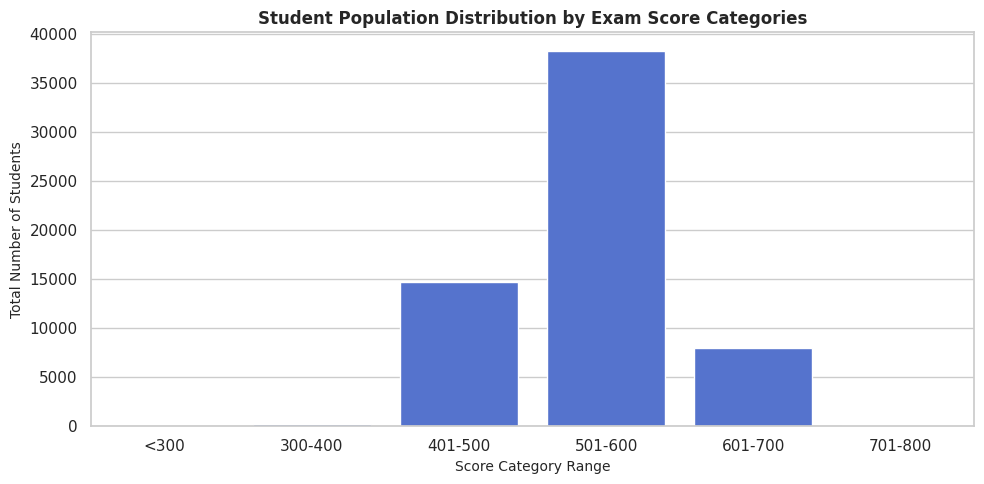

In [6]:
# Define category ranges and labels
score_bins = [0, 300, 401, 501, 601, 701, 801]
score_labels = ['<300', '300-400', '401-500', '501-600', '601-700', '701-800']

# Perform structural binning
df_scores['Score_Range'] = pd.cut(df_scores['final_score'], bins=score_bins, labels=score_labels, right=False)

# Calculate totals per category
range_distribution = df_scores['Score_Range'].value_counts().sort_index()

# Plot the student population distribution
plt.figure(figsize=(10, 5))
sns.barplot(x=range_distribution.index, y=range_distribution.values, color="royalblue")

plt.title("Student Population Distribution by Exam Score Categories", fontsize=12, fontweight='bold')
plt.xlabel("Score Category Range", fontsize=10)
plt.ylabel("Total Number of Students", fontsize=10)
plt.tight_layout()
plt.show()


As a high-tier Data Science enhancement, we isolate the top 10 elite students with the highest academic performance across the nation to observe their university placement behaviors.


--- TOP 10 ELITE ACADEMIC PERFORMERS ---
       id_user  id_first_university  final_score
41258   247133                  332   797.333333
43496   254761                  321   792.222222
1103     10834                  321   780.111111
45281   260899                  332   775.888889
1023     10322                  321   767.333333
14562   102099                  321   764.444444
6033     46697                  361   758.333333
14794   103089                  321   754.888889
54341   299703                  321   753.777778
10866    79329                  321   753.777778


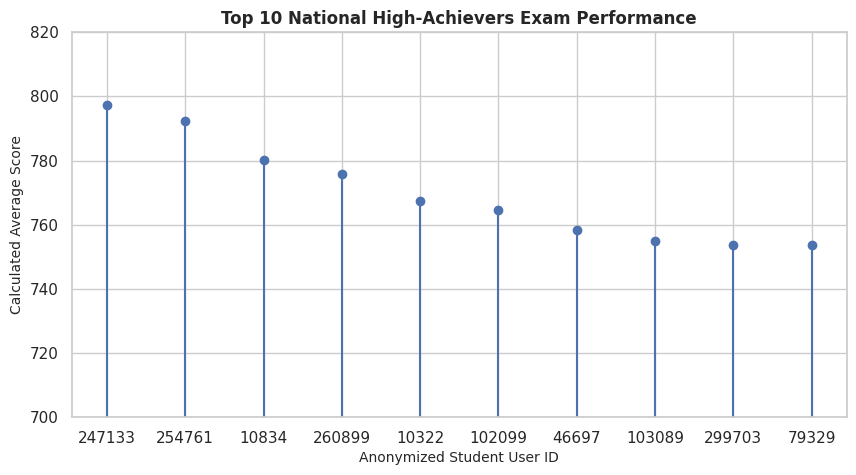

In [7]:
# Filter and sort for the top 10 elite records
top_students = df_scores.sort_values(by='final_score', ascending=False).head(10)

print("--- TOP 10 ELITE ACADEMIC PERFORMERS ---")
print(top_students[['id_user', 'id_first_university', 'final_score']])

# Plot the elite scores comparison
plt.figure(figsize=(10, 5))
plt.stem(top_students['id_user'].astype(str), top_students['final_score'])
plt.title("Top 10 National High-Achievers Exam Performance", fontsize=12, fontweight='bold')
plt.xlabel("Anonymized Student User ID", fontsize=10)
plt.ylabel("Calculated Average Score", fontsize=10)
plt.ylim(700, 820) # Focusing on high-tier grid area
plt.show()
